## principales caracteristicas
El dataset esta compuesto por audios de 1 segundo de una persona hablando una palabra en ingles, cada etiqueta de la palabra se encuentra en el nombre de la carpeta, no hay datos del hablante (ni edad, ni genero, etc.). Cada carpeta esta compuesta por vairas tomas de cada hablante esta identificado por un hash delante y luego un índice final de cada toma.

In [1]:
# ejecutar solo al principio usamos python 3.11
! conda env create -f environment.yml # entorno conda
! pip install -r requirements.txt # requirements

/bin/bash: /home/juan/miniconda3/envs/speech_cmd/lib/libtinfo.so.6: no version information available (required by /bin/bash)
2 channel Terms of Service accepted
Retrieving notices: done
Channels:
 - defaults
 - conda-forge
 - nvidia
Platform: linux-64
Solving environment: done


==> WARNING: A newer version of conda exists. <==
    current version: 26.1.1
    latest version: 26.9.4

Please update conda by running

    $ conda update -n base -c conda-forge conda



gcc_impl_linux-64-15 | 72.8 MB   |                                       |   0% 
gxx_impl_linux-64-15 | 15.1 MB   |                                       |   0% 

libstdcxx-devel_linu | 14.1 MB   |                                       |   0% 


libsanitizer-15.2.0  | 5.0 MB    |                                       |   0% 



libgcc-devel_linux-6 | 2.6 MB    |                                       |   0% 




executing-2.2.1      | 337 KB    |                                       |   0% 





gcc-15.2.0           | 30 KB  

In [22]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import os
import time
import gc
import pandas as pd
import numpy as np
import h5py
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import (StandardScaler, LabelEncoder)
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
import torch
import torchaudio
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks


In [2]:
data_dir= r"data"

In [3]:
# exploramos
datos = []
for root, dirs, files in os.walk(data_dir):
    for file in files:
        # os.path.join construye la ruta completa de forma segura para cualquier sistema operativo
        ruta_completa = os.path.join(root, file)
        print(ruta_completa)

data/X_dev_spec.h5
data/X_test_spec.h5
data/X_train_spec.h5
data/train/LICENSE
data/train/.DS_Store
data/train/dataset_con_metricas.csv
data/train/testing_list.txt
data/train/validation_list.txt
data/train/dataset_con_metricas_std+deltas.csv
data/train/README.md
data/train/one/b97c9f77_nohash_2.wav
data/train/one/c948d727_nohash_3.wav
data/train/one/05cf43ef_nohash_0.wav
data/train/one/5b09db89_nohash_1.wav
data/train/one/8134f43f_nohash_1.wav
data/train/one/a1e71565_nohash_0.wav
data/train/one/f8ad3941_nohash_0.wav
data/train/one/81a345a3_nohash_0.wav
data/train/one/f19d1738_nohash_1.wav
data/train/one/7d86b703_nohash_1.wav
data/train/one/61e2f74f_nohash_0.wav
data/train/one/14775481_nohash_0.wav
data/train/one/0a196374_nohash_0.wav
data/train/one/131e738d_nohash_3.wav
data/train/one/f104f742_nohash_0.wav
data/train/one/0d6d7360_nohash_3.wav
data/train/one/ace072ba_nohash_3.wav
data/train/one/b843de62_nohash_0.wav
data/train/one/ce0cb033_nohash_0.wav
data/train/one/76b58705_nohash_1.w

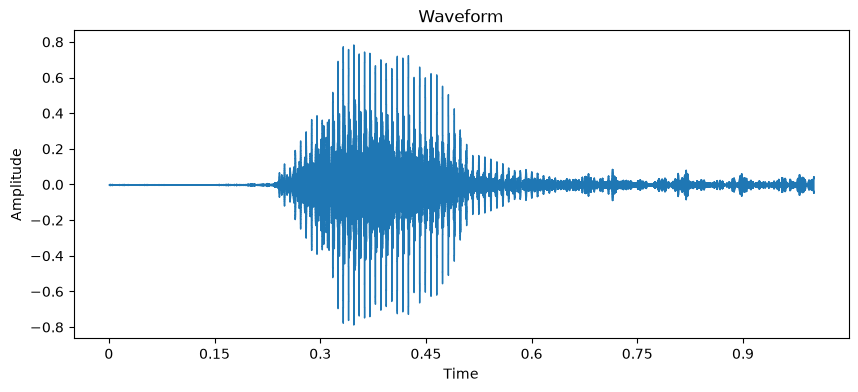

Mean: 1.7812339137890376e-05, Median: 0.00040914781857281923, Variance: 0.008622154593467712


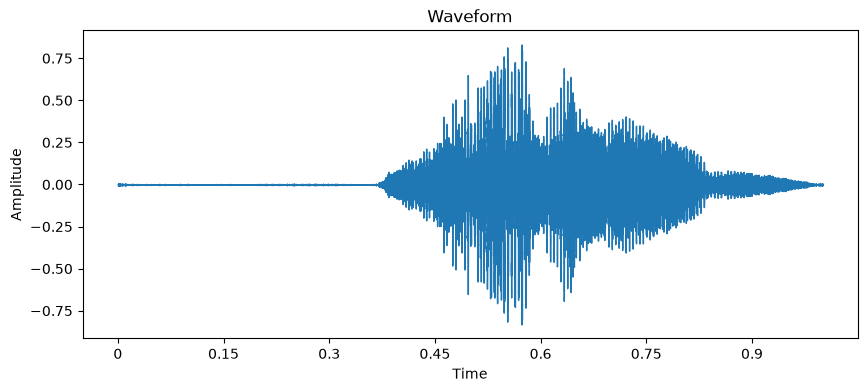

Mean: 6.048574869055301e-05, Median: 5.828906432725489e-05, Variance: 0.014457154087722301


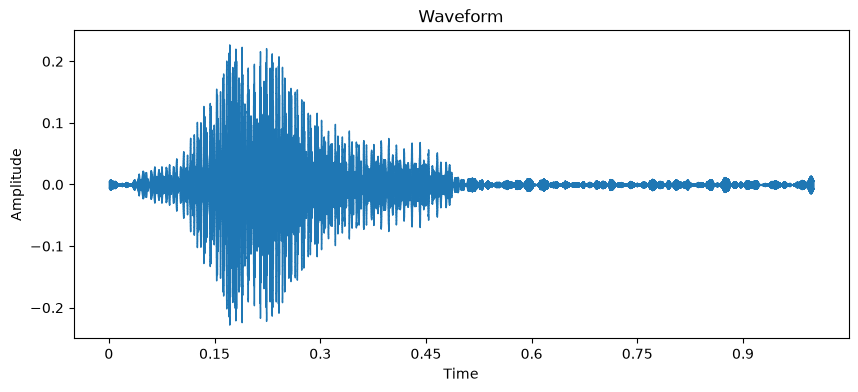

Mean: -8.249750680988654e-05, Median: 0.0007470747223123908, Variance: 0.0014567469479516149


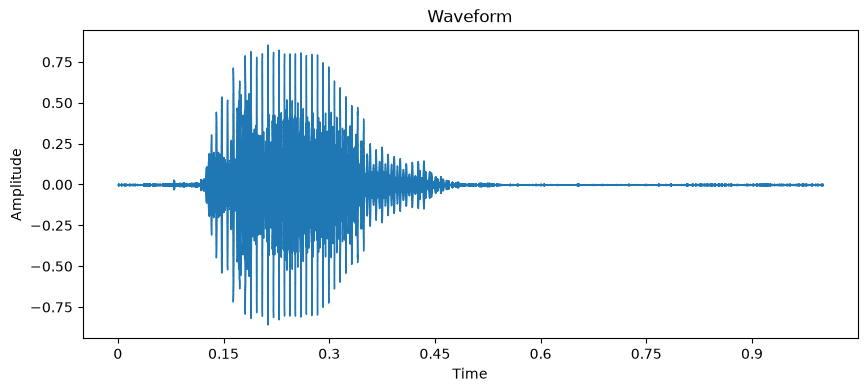

Mean: 1.0973471944453195e-05, Median: -0.0004533413448370993, Variance: 0.01739867404103279


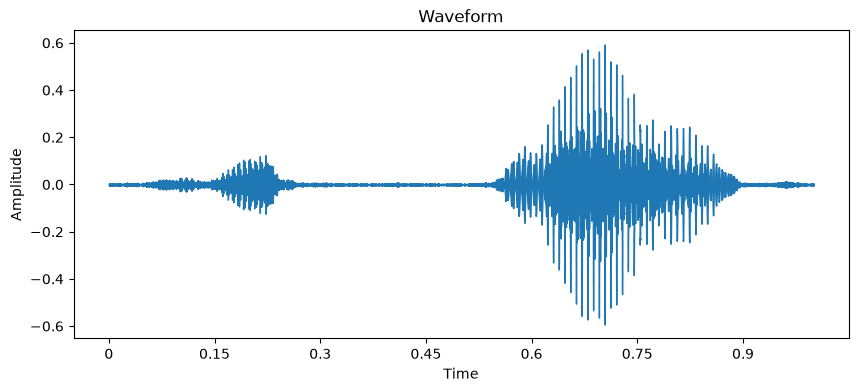

Mean: 8.492547931382433e-05, Median: 0.0005053004715591669, Variance: 0.004348552320152521


In [4]:
listado_muestra= ["data/train/one/b97c9f77_nohash_2.wav",
"data/train/one/c948d727_nohash_3.wav",
"data/train/one/05cf43ef_nohash_0.wav",
"data/train/one/5b09db89_nohash_1.wav",
"data/train/one/8134f43f_nohash_1.wav"]

for muestra in listado_muestra:
    y, sr = librosa.load(muestra)
    plt.figure(figsize=(10, 4))
    librosa.display.waveshow(y, sr=sr)
    plt.title('Waveform')
    plt.xlabel('Time')
    plt.ylabel('Amplitude')
    plt.show()
    mean = np.mean(y)
    median = np.median(y)
    variance = np.var(y)
    print(f"Mean: {mean}, Median: {median}, Variance: {variance}")

## Preparación
Como son palabras vamos a utilizar algunas herramientas que se relacionan con los fonemas para ver que tal nos va, la idea es armar un dataset con los calculos obtenidos.
Utilizaremos las primeras tres formantes.

F1:  Indica la altura o abertura de la lengua. Es bajo en vocales cerradas como [i, u] y alto en vocales abiertas como [a].

F2:  Indica la posición anterior o posterior de la lengua. Ayuda a distinguir entre vocales palatales (frente) y velares (fondo).

F3:  Aporta matices sobre la forma de los labios y la naturalidad del sonido.

Tambien es muy utilizado:

MFCC: Coeficientes Cepstrales en las Frecuencias Mel, son parámetros que representan la envolvente espectral de una señal de audio y se usan de forma masiva en el reconocimiento de voz y procesamiento de sonido.

In [5]:
data_dir = "data/train"
datos = []

for root, dirs, files in os.walk(data_dir):
  for file in files:
    # 1. Excluir todo lo que no sea .wav
    if not file.endswith(".wav"):
      continue

    ruta_completa = os.path.join(root, file)

    # 2. Obtener la palabra (nombre de la carpeta contenedora)
    word = os.path.basename(root)
    # excluyo background noise porque son audios mas largo
    if "_background_noise_" in word:
      continue

    # 3. Parsear el nombre del archivo (ej: f19d1738_nohash_1.wav)
    nombre_base = file[:-4]  # Remueve '.wav'
    if "_nohash_" in nombre_base:
      person, take = nombre_base.split("_nohash_")
    else:
      # Plan de respaldo por si algún archivo tiene otro formato
      partes = nombre_base.split("_")
      person = partes[0]
      take = partes[-1]

    # Guardar los datos en una lista de diccionarios
    datos.append(
        {"person": person, "take": take, "word": word, "path": ruta_completa}
    )

# 4. Crear el DataFrame
df = pd.DataFrame(datos)

# Agregar la columna 'id' autoincremental al inicio
df.insert(0, "id", range(len(df)))

# Ver los primeros resultados
print(df.head())

   id    person take word                                  path
0   0  b97c9f77    2  one  data/train/one/b97c9f77_nohash_2.wav
1   1  c948d727    3  one  data/train/one/c948d727_nohash_3.wav
2   2  05cf43ef    0  one  data/train/one/05cf43ef_nohash_0.wav
3   3  5b09db89    1  one  data/train/one/5b09db89_nohash_1.wav
4   4  8134f43f    1  one  data/train/one/8134f43f_nohash_1.wav


In [6]:
len(df)

105829

In [7]:
data_dir = "data/test"
datos_test = []

for root, dirs, files in os.walk(data_dir):
  for file in files:
    # 1. Excluir todo lo que no sea .wav
    if not file.endswith(".wav"):
      continue

    ruta_completa = os.path.join(root, file)

    # 2. Obtener la palabra (nombre de la carpeta contenedora)
    word = os.path.basename(root)
    if not word=='_unknown_':
      # 3. Parsear el nombre del archivo (ej: f19d1738_nohash_1.wav)
      nombre_base = file[:-4]  # Remueve '.wav'
      if "_nohash_" in nombre_base:
        person, take = nombre_base.split("_nohash_")
      else:
        # Plan de respaldo por si algún archivo tiene otro formato
        partes = nombre_base.split("_nohash_")
        person = partes[0]
        take = partes[-1]
    else: # caso especial de unknown de test
      nombre_base = file[:-8]
      if "_nohash_" in nombre_base:
        word, person, _ ,take = nombre_base.split("_")
      else:
        # Por si algún archivo tiene otro formato
        print("Error en otro formato de nombre")

    # Guardar los datos en una lista de diccionarios
    datos_test.append(
        {"person": person, "take": take, "word": word, "path": ruta_completa}
    )

# 4. Crear el DataFrame
df_test = pd.DataFrame(datos_test)

# Ver los primeros resultados
print(df_test.head())

     person take     word                                               path
0  af405b69    0      wow  data/test/_unknown_/wow_af405b69_nohash_0.wav.wav
1  bb05582b    0     zero  data/test/_unknown_/zero_bb05582b_nohash_0.wav...
2  4c6167ca    5  forward  data/test/_unknown_/forward_4c6167ca_nohash_5....
3  f9643d42    2  forward  data/test/_unknown_/forward_f9643d42_nohash_2....
4  91b03183    3    three  data/test/_unknown_/three_91b03183_nohash_3.wa...


In [8]:
len(df_test) # 5%

4890

In [9]:
train_speakers = set(df['person'])
test_speakers = set(df_test['person'])

overlap = train_speakers.intersection(test_speakers)

print(f"Hablantes repetidos (mezclados): {len(overlap)}")

Hablantes repetidos (mezclados): 239


In [ ]:
# con CPU
# Listas temporales para almacenar los nuevos valores
f1_list = []
f2_list = []
f3_list = []
mfcc_lists = []

# Iterar sobre las rutas de los audios que ya están en el DataFrame
for ruta_completa in df["path"]:
  try:
    # 1. Cargar el audio
    y, sr = librosa.load(ruta_completa, sr=None)

    # 2. Calcular MFCCs (media a lo largo del tiempo)
    mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
    mfccs_mean = np.mean(mfccs, axis=1)  # Vector de 13 valores
    mfcc_lists.append(mfccs_mean)

    # 3. Estimar Formantes (F1, F2, F3) usando LPC
    y_preemph = librosa.effects.preemphasis(y)
    lpc_coeffs = librosa.lpc(y_preemph, order=int(sr / 2000 + 2))

    roots = np.roots(lpc_coeffs)
    roots = roots[np.imag(roots) > 0]
    ang = np.angle(roots)
    frequencies = sorted(ang * (sr / (2 * np.pi)))

    f1 = frequencies[0] if len(frequencies) > 0 else np.nan
    f2 = frequencies[1] if len(frequencies) > 1 else np.nan
    f3 = frequencies[2] if len(frequencies) > 2 else np.nan

    f1_list.append(f1)
    f2_list.append(f2)
    f3_list.append(f3)

  except Exception as e:
    print(f"Error procesando {ruta_completa}: {e}")
    f1_list.append(np.nan)
    f2_list.append(np.nan)
    f3_list.append(np.nan)
    mfcc_lists.append([np.nan] * 13)

# 4. Agregar las columnas de Formantes al DataFrame
df["F1"] = f1_list
df["F2"] = f2_list
df["F3"] = f3_list

# 5. Convertir la lista de MFCCs en un DataFrame auxiliar y unirlos al original
mfcc_df = pd.DataFrame(
    mfcc_lists, columns=[f"MFCC_{i}" for i in range(1, 14)]
)
df = pd.concat([df.reset_index(drop=True), mfcc_df], axis=1)

# Ver las primeras filas con las nuevas columnas incorporadas
print(df[["person", "word", "F1", "F2", "F3", "MFCC_1"]].head())

In [ ]:
# con GPU

# 1. Configurar el dispositivo (CUDA)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Calculando MFCCs en: {device}")

# 2. Definir la transformación de MFCC en PyTorch y enviarla a la GPU
mfcc_transform = torchaudio.transforms.MFCC(
    sample_rate=16000,
    n_mfcc=13,
    melkwargs={"n_fft": 400, "hop_length": 160, "n_mels": 23},
).to(device)

mfcc_lists = []
f1_list, f2_list, f3_list = [], [], []

for ruta_completa in df["path"]:
  try:
    # A. Cargar el audio con Librosa (Evita por completo el error de TorchCodec)
    y, sr = librosa.load(ruta_completa, sr=16000)

    # Convertir el array a Tensor de PyTorch y enviarlo a la GPU (CUDA)
    waveform = torch.tensor(y, dtype=torch.float32).unsqueeze(0).to(device)

    # B. Calcular MFCCs directamente en la GPU
    mfccs = mfcc_transform(waveform)  # Forma: [1, n_mfcc, tiempo]
    mfccs_mean = mfccs.mean(dim=-1).squeeze(0).cpu().numpy()  # Promedio y vuelta a CPU
    mfcc_lists.append(mfccs_mean)

    # C. Cálculo de Formantes (F1, F2, F3) usando LPC en CPU
    y_preemph = librosa.effects.preemphasis(y)
    lpc_coeffs = librosa.lpc(y_preemph, order=int(sr / 2000 + 2))

    roots = np.roots(lpc_coeffs)
    roots = roots[np.imag(roots) > 0]
    ang = np.angle(roots)
    frequencies = sorted(ang * (sr / (2 * np.pi)))

    f1_list.append(frequencies[0] if len(frequencies) > 0 else np.nan)
    f2_list.append(frequencies[1] if len(frequencies) > 1 else np.nan)
    f3_list.append(frequencies[2] if len(frequencies) > 2 else np.nan)

  except Exception as e:
    print(f"Error procesando {ruta_completa}: {e}")
    mfcc_lists.append([np.nan] * 13)
    f1_list.append(np.nan)
    f2_list.append(np.nan)
    f3_list.append(np.nan)

# 3. Integrar los resultados al DataFrame original
df["F1"] = f1_list
df["F2"] = f2_list
df["F3"] = f3_list

mfcc_df = pd.DataFrame(
    mfcc_lists, columns=[f"MFCC_{i}" for i in range(1, 14)]
)
df = pd.concat([df.reset_index(drop=True), mfcc_df], axis=1)

print(df[["person", "word", "F1", "MFCC_1"]].head())

In [ ]:
# guardo el dataset calculado para evitar volver a calcular
ruta_archivo_calculado = f"data/train/dataset_con_metricas.csv"
df.to_csv(ruta_archivo_calculado, index=False)

In [10]:
# leer el dataset calculado para evitar volver a calcular
ruta_archivo_calculado = f"data/train/dataset_con_metricas.csv"
df = pd.read_csv(ruta_archivo_calculado)

In [11]:
# 1. Contar cuántos NaN hay en total en todo el DataFrame
total_nans = df.isna().sum().sum()
print(f"Total de valores NaN en el DataFrame: {total_nans}")

# 2. Ver cuántos NaN hay por cada columna (muestra solo las que tienen alguno)
nans_por_columna = df.isna().sum()
print("\nConteo de NaN por columna:")
print(nans_por_columna[nans_por_columna > 0])

# 3. Filtrar y ver cuáles filas (audios) tienen valores NaN
filas_con_nans = df[df.isna().any(axis=1)]

Total de valores NaN en el DataFrame: 2

Conteo de NaN por columna:
F3    2
dtype: int64


In [12]:
df_limpio = df.dropna().reset_index(drop=True)

## Baseline Etapa 1

Ya con este dataset formado y caracteristicas calculadas probamos regression logistica

In [13]:
# df = pd.read_csv(ruta_archivo_calculado)
df = df_limpio.copy()
y = df["word"]
columnas_a_excluir = ["person", "take", "word"] # el path lo conservamos hasta luego del split
X = df.drop(columns=[col for col in columnas_a_excluir if col in df.columns])


print(f"Tamaño total del dataset: {X.shape} audios con {X.shape[1]-1} características.") # restamos path

Tamaño total del dataset: (105827, 18) audios con 17 características.


In [14]:
# 1. Partición de Datos (Estrategia Train / Dev / Test)
# Primero separamos el Train (80%) del resto (20%)
# Los datos finales de test separados ya en la descarga del dataset representan un 5% del train
X_train, X_dev, y_train, y_dev = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y) #separamos asi para poder tener el mismo conjunto
# para la etapa 2 que se planteó en clase de audio (espectrograma)
X_train_path=X_train.pop('path') # conservamos y quitamos el path de X
X_dev_path=X_dev.pop('path')



print(f"Datos de Entrenamiento (Train): {X_train.shape}")

# 2. Escalar los datos (fundamental para que converjan los coeficientes de audio)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_dev_scaled = scaler.transform(X_dev)
print(f"Datos de Desarrollo (Dev): {X_dev.shape}")

Datos de Entrenamiento (Train): (84661, 17)
Datos de Desarrollo (Dev): (21166, 17)


In [19]:
# 3. Construcción del Modelo Base (Baseline)
modelo_base = LogisticRegression(C=1, max_iter=200, verbose=1)
modelo_base.fit(X_train_scaled, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",200
,"verbose verbose: int, default=0For the liblinear and lbfgs solvers set verbose to any positivenumber for verbosity.",1
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None


In [20]:
# Realizar predicciones usando el conjunto de desarrollo/prueba escalado
y_pred_dev = modelo_base.predict(X_dev_scaled)

# Cálculos de Métricas (usando average='weighted' por ser multiclase)
matriz_conf = confusion_matrix(y_dev, y_pred_dev)
exactitud = accuracy_score(y_dev, y_pred_dev)
precision = precision_score(y_dev, y_pred_dev, average="weighted")
recall = recall_score(y_dev, y_pred_dev, average="weighted")
f1 = f1_score(
    y_dev, y_pred_dev, average="weighted"
)  # Nuestra métrica de número único

print("\n--- RESULTADOS EN EL CONJUNTO DEV ---")
print("Matriz de Confusión:")
print(matriz_conf)
print(f"Exactitud (Accuracy): {exactitud:.4f}")
print(f"Precisión:            {precision:.4f}")
print(f"Exhaustividad (Recall):{recall:.4f}")
print(f"Puntaje F1 (F1-Score): {f1:.4f}  <-- Métrica de número único")


--- RESULTADOS EN EL CONJUNTO DEV ---
Matriz de Confusión:
[[195   9   0 ...   0   0   0]
 [ 15 298   0 ...   0   0   0]
 [  0   0 294 ...   0  20   0]
 ...
 [  0   0   0 ... 279   0  11]
 [  0   0  16 ...   0 681   0]
 [  0   0   0 ...   2   0 705]]
Exactitud (Accuracy): 0.7591
Precisión:            0.7577
Exhaustividad (Recall):0.7591
Puntaje F1 (F1-Score): 0.7566  <-- Métrica de número único


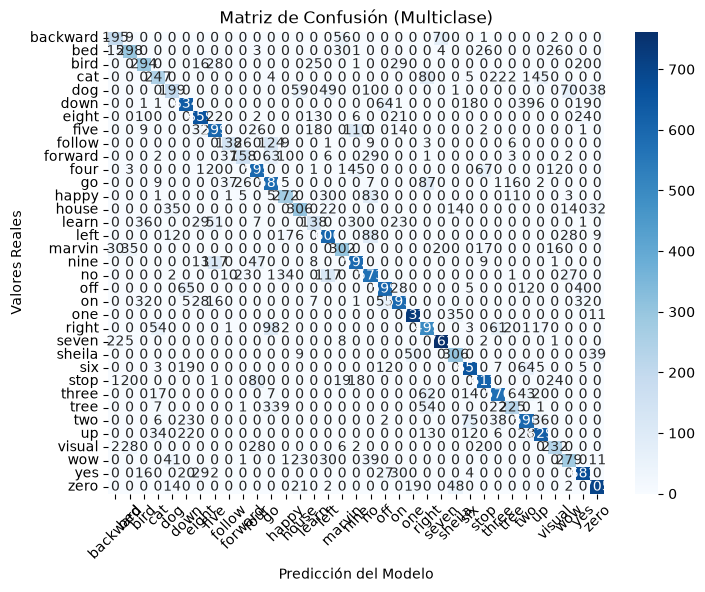

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

clases = modelo_base.classes_

# Crear un mapa de calor de la matriz de confusión
plt.figure(
    figsize=(8, 6)
) 
sns.heatmap(
    matriz_conf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=clases,
    yticklabels=clases,
)

plt.xlabel("Predicción del Modelo")
plt.ylabel("Valores Reales")
plt.title("Matriz de Confusión (Multiclase)")
plt.xticks(rotation=45) 
plt.yticks(rotation=0)
plt.show()

In [22]:
from sklearn.linear_model import LogisticRegressionCV

# Busca el mejor 'C' entre una lista de opciones usando validación cruzada (cv=5)
modelo_cv = LogisticRegressionCV(
    Cs=[0.001, 0.01, 0.1, 1, 10, 100],
    cv=5,
    penalty="l2",
    solver="lbfgs",
    max_iter=300,
    random_state=42,
)

# Entrenar el modelo optimizado
modelo_cv.fit(X_train_scaled, y_train)

# Ver cuál fue el mejor valor de C que eligió automáticamente
print(f"Mejor valor de C encontrado: {modelo_cv.C_[0]}")
print(f"Precisión con el mejor C: {modelo_cv.score(X_dev_scaled, y_dev):.4f}")

/home/juan/miniconda3/envs/speech_cmd/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/juan/miniconda3/envs/speech_cmd/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:2102: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' and 'Cs' instead. Use l1_ratios=(0,) instead of penalty='l2', l1_ratios=(1,) instead of penalty='l1', l1_ratios set to floats between 0 and 1 instead of penalty='elasticnet', and Cs=(np.inf,) instead of penalty=None.
  warnings.warn(
/home/juan/miniconda3/envs/speech_cmd/lib/python3.11/site-packages/sklearn/linear_model/_logistic

Mejor valor de C encontrado: 100.0
Precisión con el mejor C: 0.9187


No mejora demasiado vamos a ir por otro intento sumando algunos coeficientes para ver de capturar los cambios en fonemas compuestos.

Agregando la desviacion estandar en los coeficientes de mel y tambien deltas (derivadas temporales de primer y segundo orden)

In [23]:
# Forzar backend de sonido si es necesario
try:
  torchaudio.set_audio_backend("soundfile")
except:
  pass

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Procesando características avanzadas en: {device}")

# Transformaciones en PyTorch/TorchAudio
mfcc_transform = torchaudio.transforms.MFCC(
    sample_rate=16000,
    n_mfcc=13,
    melkwargs={"n_fft": 400, "hop_length": 160, "n_mels": 23},
).to(device)

delta_transform = torchaudio.transforms.ComputeDeltas().to(device)

datos_procesados = []

for ruta_completa in df["path"]:
  try:
    # 1. Cargar audio con Librosa y enviar a PyTorch/CUDA
    y, sr = librosa.load(ruta_completa, sr=16000)
    waveform = torch.tensor(y, dtype=torch.float32).unsqueeze(0).to(device)

    # 2. Calcular MFCCs [1, 13, tiempo]
    mfccs = mfcc_transform(waveform)

    # 3. Calcular Deltas (velocidad) y Delta-Deltas (aceleración) de los MFCCs
    mfccs_delta = delta_transform(mfccs)
    mfccs_delta2 = delta_transform(mfccs_delta)

    # 4. Extraer estadísticas temporales para cada uno (Media y Desviación Estándar)
    # Esto resume la dinámica temporal en un vector fijo por cada audio
    mfcc_mean = mfccs.mean(dim=-1).squeeze(0).cpu().numpy()
    mfcc_std = mfccs.std(dim=-1).squeeze(0).cpu().numpy()

    delta_mean = mfccs_delta.mean(dim=-1).squeeze(0).cpu().numpy()
    delta_std = mfccs_delta.std(dim=-1).squeeze(0).cpu().numpy()

    delta2_mean = mfccs_delta2.mean(dim=-1).squeeze(0).cpu().numpy()
    delta2_std = mfccs_delta2.std(dim=-1).squeeze(0).cpu().numpy()

    # 5. Cálculo de Formantes (F1, F2, F3) usando LPC en CPU
    y_preemph = librosa.effects.preemphasis(y)
    lpc_coeffs = librosa.lpc(y_preemph, order=int(sr / 2000 + 2))
    roots = np.roots(lpc_coeffs)
    roots = roots[np.imag(roots) > 0]
    ang = np.angle(roots)
    frequencies = sorted(ang * (sr / (2 * np.pi)))

    f1 = frequencies[0] if len(frequencies) > 0 else np.nan
    f2 = frequencies[1] if len(frequencies) > 1 else np.nan
    f3 = frequencies[2] if len(frequencies) > 2 else np.nan

    # Estructura base de la fila con metadatos y formantes
    fila = {
        "person": df.loc[df["path"] == ruta_completa, "person"].values[0],
        "take": df.loc[df["path"] == ruta_completa, "take"].values[0],
        "word": df.loc[df["path"] == ruta_completa, "word"].values[0],
        "F1": f1,
        "F2": f2,
        "F3": f3,
    }

    # Agregar dinámicamente las columnas al diccionario
    for i in range(13):
      fila[f"MFCC_{i+1}_mean"] = mfcc_mean[i]
      fila[f"MFCC_{i+1}_std"] = mfcc_std[i]
      fila[f"Delta_{i+1}_mean"] = delta_mean[i]
      fila[f"Delta_{i+1}_std"] = delta_std[i]
      fila[f"Delta2_{i+1}_mean"] = delta2_mean[i]
      fila[f"Delta2_{i+1}_std"] = delta2_std[i]

    fila["path"] = ruta_completa
    datos_procesados.append(fila)

  except Exception as e:
    print(f"Error procesando {ruta_completa}: {e}")

# Reconstruir el DataFrame completo con las nuevas características enriquecidas
df_enriquecido = pd.DataFrame(datos_procesados)

# guardo el dataset calculado para evitar volver a calcular
ruta_archivo_calculado = f"data/train/dataset_con_metricas_std+deltas.csv"
df_enriquecido.to_csv(ruta_archivo_calculado, index=False)


Procesando características avanzadas en: cuda


KeyboardInterrupt: 

In [15]:

# leer el dataset calculado para evitar volver a calcular
ruta_archivo_calculado = f"data/train/dataset_con_metricas_std+deltas.csv"
df_enriquecido = pd.read_csv(ruta_archivo_calculado)

# Reemplazar el antiguo df por el enriquecido
X_train_enriquecido = pd.merge(X_train_path.copy(), df_enriquecido, on="path", how="left")
X_dev_enriquecido = pd.merge(X_dev_path.copy(), df_enriquecido, on="path", how="left")


In [16]:
# 1. Contar cuántos NaN hay en total en todo el DataFrame
total_nans = X_train_enriquecido .isna().sum().sum()
print(f"Total de valores NaN en el X_train: {total_nans}")

# 2. Ver cuántos NaN hay por cada columna (muestra solo las que tienen alguno)
nans_por_columna = X_train_enriquecido .isna().sum()
print("\nConteo de NaN por columna:")
print(nans_por_columna[nans_por_columna > 0])

# 3. Filtrar y ver cuáles filas (audios) tienen valores NaN
filas_con_nans = X_train_enriquecido [X_train_enriquecido .isna().any(axis=1)]

# 1. Contar cuántos NaN hay en total en todo el DataFrame
total_nans = X_dev_enriquecido.isna().sum().sum()
print(f"Total de valores NaN en el X_dev: {total_nans}")

# 2. Ver cuántos NaN hay por cada columna (muestra solo las que tienen alguno)
nans_por_columna = X_dev_enriquecido.isna().sum()
print("\nConteo de NaN por columna:")
print(nans_por_columna[nans_por_columna > 0])

# 3. Filtrar y ver cuáles filas (audios) tienen valores NaN
filas_con_nans = X_dev_enriquecido[X_dev_enriquecido.isna().any(axis=1)]

Total de valores NaN en el X_train: 0

Conteo de NaN por columna:
Series([], dtype: int64)
Total de valores NaN en el X_dev: 0

Conteo de NaN por columna:
Series([], dtype: int64)


In [17]:

X_train = X_train_path.copy().drop(columns=['path','take','person','word'])
X_dev = X_dev_path.copy().drop(columns=['path','take','person','word'])

print(f"Datos de Entrenamiento (Train): {X_train.shape}")

# 2. Escalar los datos (fundamental para que converjan los coeficientes de audio)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_dev_scaled = scaler.transform(X_dev)
print(f"Datos de Desarrollo (Dev): {X_dev.shape}")

Datos de Entrenamiento (Train): (84661,)


ValueError: could not convert string to float: 'data/train/up/2bdbe5f7_nohash_1.wav'

In [28]:
# 3. Construcción del Modelo Base (Baseline)
modelo_base = LogisticRegression(C=1, max_iter=200, verbose=1)
modelo_base.fit(X_train_scaled, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",200
,"verbose verbose: int, default=0For the liblinear and lbfgs solvers set verbose to any positivenumber for verbosity.",1
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None


In [29]:
# Realizar predicciones usando el conjunto de desarrollo/prueba escalado
y_pred_dev = modelo_base.predict(X_dev_scaled)

# Cálculos de Métricas (usando average='weighted' por ser multiclase)
matriz_conf = confusion_matrix(y_dev, y_pred_dev)
exactitud = accuracy_score(y_dev, y_pred_dev)
precision = precision_score(y_dev, y_pred_dev, average="weighted")
recall = recall_score(y_dev, y_pred_dev, average="weighted")
f1 = f1_score(
    y_dev, y_pred_dev, average="weighted"
)  # Nuestra métrica de número único

print("\n--- RESULTADOS EN EL CONJUNTO DEV ---")
print("Matriz de Confusión:")
print(matriz_conf)
print(f"Exactitud (Accuracy): {exactitud:.4f}")
print(f"Precisión:            {precision:.4f}")
print(f"Exhaustividad (Recall):{recall:.4f}")
print(f"Puntaje F1 (F1-Score): {f1:.4f}  <-- Métrica de número único")


--- RESULTADOS EN EL CONJUNTO DEV ---
Matriz de Confusión:
[[168   6   6 ...   4   0   2]
 [  3 217   6 ...   3   3   2]
 [  4  12 277 ...   0   0   9]
 ...
 [  0   2   1 ... 256   5   5]
 [  0   6   1 ...   4 567  27]
 [  3   3   7 ...   2  18 521]]
Exactitud (Accuracy): 0.5761
Precisión:            0.5741
Exhaustividad (Recall):0.5761
Puntaje F1 (F1-Score): 0.5743  <-- Métrica de número único


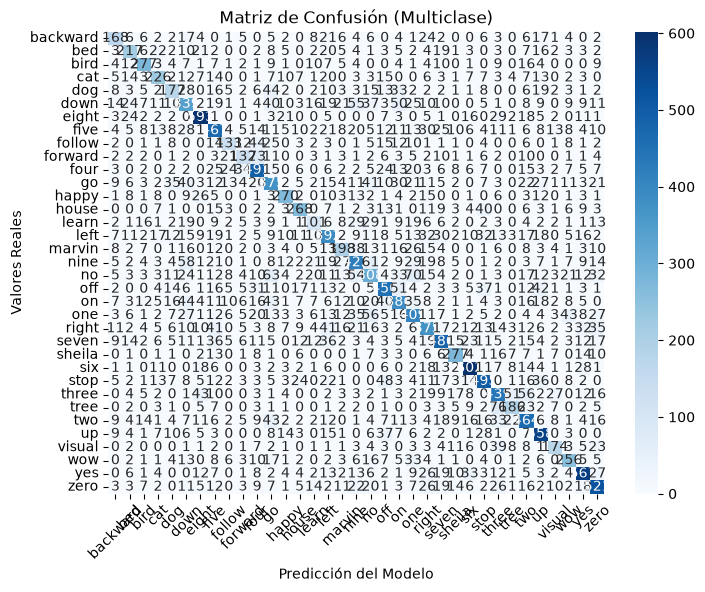

In [30]:
clases = modelo_base.classes_

# Crear un mapa de calor de la matriz de confusión
plt.figure(
    figsize=(8, 6)
) 
sns.heatmap(
    matriz_conf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=clases,
    yticklabels=clases,
)

plt.xlabel("Predicción del Modelo")
plt.ylabel("Valores Reales")
plt.title("Matriz de Confusión (Multiclase)")
plt.xticks(rotation=45) 
plt.yticks(rotation=0)
plt.show()

In [31]:
# Busca el mejor 'C' entre una lista de opciones usando validación cruzada (cv=5)
modelo_cv = LogisticRegressionCV(
    Cs=[0.001, 0.01, 0.1, 1, 10, 100],
    cv=5,
    penalty="l2",
    solver="lbfgs",
    max_iter=300,
    random_state=42,
)

# Entrenar el modelo optimizado
modelo_cv.fit(X_train_scaled, y_train)

# Ver cuál fue el mejor valor de C que eligió automáticamente
print(f"Mejor valor de C encontrado: {modelo_cv.C_[0]}")
print(f"Precisión con el mejor C: {modelo_cv.score(X_dev_scaled, y_dev):.4f}")

/home/juan/miniconda3/envs/speech_cmd/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/juan/miniconda3/envs/speech_cmd/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:2102: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' and 'Cs' instead. Use l1_ratios=(0,) instead of penalty='l2', l1_ratios=(1,) instead of penalty='l1', l1_ratios set to floats between 0 and 1 instead of penalty='elasticnet', and Cs=(np.inf,) instead of penalty=None.
  warnings.warn(
/home/juan/miniconda3/envs/speech_cmd/lib/python3.11/site-packages/sklearn/linear_model/_logistic

KeyboardInterrupt: 


# De la señal al espectrograma

In [22]:
def leer_audio(path):
    audio_bin = tf.io.read_file(path)
    waveform, sr = tf.audio.decode_wav(audio_bin, desired_channels=1)
    return waveform.numpy()[:, 0], int(sr.numpy())

labels, speakers, waves, rates = [], [], [], []
for f in df['path']:
    # word, speaker, _ = f.replace(".wav", "").split("_")
    w, sr = leer_audio(f)
    #labels.append(int(digit))
    #speakers.append(str(speaker))
    waves.append(w)
    rates.append(sr)

#labels = np.array(labels)
#speakers = np.array(speakers)

print("Frecuencias de muestreo encontradas:", set(rates))
#print("Locutores:", sorted(set(speakers)))
#print("Audios por dígito:", np.bincount(labels))
print(f"Duración promedio: {np.mean([len(w) for w in waves]) / rates[0]:.3f} s")

W0000 00:00:1793727740.453227   28542 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
I0000 00:00:1793727740.454599   28542 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 2602 MB memory:  -> device: 0, name: NVIDIA GeForce GTX 1650, pci bus id: 0000:01:00.0, compute capability: 7.5


Frecuencias de muestreo encontradas: {16000}
Duración promedio: 0.981 s


In [18]:
X_train_enriquecido

,path,person,take,word,F1,F2,F3,MFCC_1_mean,MFCC_1_std,Delta_1_mean,...,Delta_12_mean,Delta_12_std,Delta2_12_mean,Delta2_12_std,MFCC_13_mean,MFCC_13_std,Delta_13_mean,Delta_13_std,Delta2_13_mean,Delta2_13_std
0,data/train/up/2bdbe5f7_nohash_1.wav,2bdbe5f7,1,up,1123.11450,1331.53030,3383.8762,-103.939450,62.631863,0.036274,...,0.070292,1.080711,0.008366,0.468010,-3.226689,4.425767,0.007325,1.392279,0.022883,0.621085
1,data/train/on/a4383927_nohash_0.wav,a4383927,0,on,457.78085,1003.43604,3552.5840,-134.138030,62.312912,1.138080,...,-0.111004,1.033263,0.021855,0.434563,-2.651826,3.298811,0.020709,0.897293,0.008381,0.372714
2,data/train/seven/d98dd124_nohash_1.wav,d98dd124,1,seven,732.88983,2220.78830,3889.1821,-83.506450,63.840996,-0.267171,...,0.027586,1.244155,0.012986,0.512375,-2.243320,5.386457,0.001497,1.533369,0.012785,0.591638
3,data/train/nine/49f30eed_nohash_0.wav,49f30eed,0,nine,757.84656,1672.13120,2803.2295,-148.553960,53.438313,-0.176678,...,0.052724,1.119765,0.051297,0.481527,-1.708999,3.780096,-0.017175,1.176301,0.036691,0.480788
4,data/train/up/2fa39636_nohash_2.wav,2fa39636,2,up,704.83240,2569.59840,3753.9075,-78.167370,19.087704,-0.056115,...,0.034665,0.799138,-0.023435,0.346659,-1.326251,2.959735,-0.023452,0.807700,-0.015599,0.328065
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84656,data/train/six/38c30a4a_nohash_1.wav,38c30a4a,1,six,842.76570,2201.94650,4418.4287,-116.342910,43.637936,0.305868,...,-0.007008,1.078674,0.022094,0.519094,-2.719452,2.140921,-0.007758,0.748667,0.000578,0.345575
84657,data/train/one/525eaa62_nohash_1.wav,525eaa62,1,one,785.37256,849.47015,3840.2437,-109.281790,74.100820,0.742156,...,-0.034422,0.996819,0.014452,0.449999,-0.127840,2.660720,0.016929,0.879323,-0.007476,0.382383
84658,data/train/marvin/0d2bcf9d_nohash_1.wav,0d2bcf9d,1,marvin,758.14185,2207.40970,4028.8677,-63.899530,34.096893,-0.201669,...,0.019277,0.957182,0.003467,0.425528,-1.175309,3.621308,-0.009375,0.900693,0.014342,0.386542
84659,data/train/stop/39afb88e_nohash_0.wav,39afb88e,0,stop,696.05817,3552.25020,5078.1330,-121.831566,29.695831,0.159337,...,0.004496,1.110884,0.007190,0.475177,-0.212867,4.328245,-0.049737,1.206735,0.018335,0.528002


In [69]:
SR = 16000 # aca mantenemos 16000 porque en el baseline usamos ese sample_rate
N_MAX = SR  # clips de 1 segundo
FRAME_LENGTH = 512 # ventana de 32 ms en 16Khz
FRAME_STEP = 246  # salto de 16 ms en 16Khz
batch_size = 128

def ajustar_largo(w, n=N_MAX):
    w = w[:n]
    return np.pad(w, (0, n - len(w)))

def extraer_espectrograma(waves_batch):
    stft = tf.signal.stft(
        waves_batch,
        frame_length=FRAME_LENGTH,
        frame_step=FRAME_STEP,
        fft_length=FRAME_LENGTH,
    )
    return tf.math.log(tf.abs(stft) + 1e-6)[..., tf.newaxis].numpy()

# --- Procesamiento y Escritura Directa a Disco ---

#TRAIN

listado_rutas =X_train_path

with h5py.File(r"data/X_train_spec.h5", "w") as hf:
    dataset_x = None  # Lo inicializaremos con el primer lote
    
    for i in range(0, len(listado_rutas), batch_size):
        lote_rutas = listado_rutas[i:i + batch_size]
        waves_batch = []
        
        # 1. Cargar y procesar audios del lote
        for ruta in lote_rutas:
            w_orig, sr_orig = librosa.load(ruta, sr=None)
            if sr_orig != SR:
                w_orig = librosa.resample(w_orig, orig_sr=sr_orig, target_sr=SR)
            waves_batch.append(ajustar_largo(w_orig))
        
        X_wave_lote = np.stack(waves_batch).astype(np.float32)
        spec_lote = extraer_espectrograma(X_wave_lote)
        
        # 2. Guardar en el HDF5
        if dataset_x is None:
            # Si es el primer lote, creamos el "molde" en el archivo
            forma_base = spec_lote.shape[1:]  # (tiempo, frecuencia, canal)
            # maxshape con 'None' permite que el dataset crezca infinitamente hacia abajo
            dataset_x = hf.create_dataset("X_spec", shape=(0, *forma_base), 
                                          maxshape=(None, *forma_base), 
                                          dtype='float32', compression="gzip")
            
        # Agrandamos el archivo en disco para que entre el nuevo lote
        dataset_x.resize(dataset_x.shape[0] + spec_lote.shape[0], axis=0)
        # Pegamos los datos del lote en las nuevas filas generadas
        dataset_x[-spec_lote.shape[0]:] = spec_lote
        
        print(f"Procesados y guardados: {dataset_x.shape[0]} / {len(listado_rutas)}")



# DEV
listado_rutas =X_dev_path

with h5py.File(r"data/X_dev_spec.h5", "w") as hf:
    dataset_x = None  # Lo inicializaremos con el primer lote
    
    for i in range(0, len(listado_rutas), batch_size):
        lote_rutas = listado_rutas[i:i + batch_size]
        waves_batch = []
        
        # 1. Cargar y procesar audios del lote
        for ruta in lote_rutas:
            w_orig, sr_orig = librosa.load(ruta, sr=None)
            if sr_orig != SR:
                w_orig = librosa.resample(w_orig, orig_sr=sr_orig, target_sr=SR)
            waves_batch.append(ajustar_largo(w_orig))
        
        X_wave_lote = np.stack(waves_batch).astype(np.float32)
        spec_lote = extraer_espectrograma(X_wave_lote)
        
        # 2. Guardar en el HDF5
        if dataset_x is None:
            # Si es el primer lote, creamos el "molde" en el archivo
            forma_base = spec_lote.shape[1:]  # (tiempo, frecuencia, canal)
            # maxshape con 'None' permite que el dataset crezca infinitamente hacia abajo
            dataset_x = hf.create_dataset("X_spec", shape=(0, *forma_base), 
                                          maxshape=(None, *forma_base), 
                                          dtype='float32', compression="gzip")
            
        # Agrandamos el archivo en disco para que entre el nuevo lote
        dataset_x.resize(dataset_x.shape[0] + spec_lote.shape[0], axis=0)
        # Pegamos los datos del lote en las nuevas filas generadas
        dataset_x[-spec_lote.shape[0]:] = spec_lote
        
        print(f"Procesados y guardados: {dataset_x.shape[0]} / {len(listado_rutas)}")


print("¡Procesamiento finalizado y asegurado en el disco duro!")

Procesados y guardados: 128 / 84661
Procesados y guardados: 256 / 84661
Procesados y guardados: 384 / 84661
Procesados y guardados: 512 / 84661
Procesados y guardados: 640 / 84661
Procesados y guardados: 768 / 84661
Procesados y guardados: 896 / 84661
Procesados y guardados: 1024 / 84661
Procesados y guardados: 1152 / 84661
Procesados y guardados: 1280 / 84661
Procesados y guardados: 1408 / 84661
Procesados y guardados: 1536 / 84661
Procesados y guardados: 1664 / 84661
Procesados y guardados: 1792 / 84661
Procesados y guardados: 1920 / 84661
Procesados y guardados: 2048 / 84661
Procesados y guardados: 2176 / 84661
Procesados y guardados: 2304 / 84661
Procesados y guardados: 2432 / 84661
Procesados y guardados: 2560 / 84661
Procesados y guardados: 2688 / 84661
Procesados y guardados: 2816 / 84661
Procesados y guardados: 2944 / 84661
Procesados y guardados: 3072 / 84661
Procesados y guardados: 3200 / 84661
Procesados y guardados: 3328 / 84661
Procesados y guardados: 3456 / 84661
Procesad

In [29]:
df_test.value_counts('word')

word
up           425
yes          419
left         412
stop         411
_silence_    408
down         406
no           405
go           402
off          402
right        396
on           396
eight         34
six           28
three         26
one           25
zero          24
nine          24
five          23
happy         21
two           20
seven         18
four          18
sheila        17
wow           15
forward       13
marvin        11
bed           10
tree          10
cat           10
house         10
bird          10
learn         10
backward       9
follow         9
dog            7
visual         6
Name: count, dtype: int64

In [74]:
# TEST
listado_rutas =df_test['path']

with h5py.File(r"data/X_test_spec.h5", "w") as hf:
    dataset_x = None  # Lo inicializaremos con el primer lote
    
    for i in range(0, len(listado_rutas), batch_size):
        lote_rutas = listado_rutas[i:i + batch_size]
        waves_batch = []
        
        # 1. Cargar y procesar audios del lote
        for ruta in lote_rutas:
            w_orig, sr_orig = librosa.load(ruta, sr=None)
            if sr_orig != SR:
                w_orig = librosa.resample(w_orig, orig_sr=sr_orig, target_sr=SR)
            waves_batch.append(ajustar_largo(w_orig))
        
        X_wave_lote = np.stack(waves_batch).astype(np.float32)
        spec_lote = extraer_espectrograma(X_wave_lote)
        
        # 2. Guardar en el HDF5
        if dataset_x is None:
            # Si es el primer lote, creamos el "molde" en el archivo
            forma_base = spec_lote.shape[1:]  # (tiempo, frecuencia, canal)
            # maxshape con 'None' permite que el dataset crezca infinitamente hacia abajo
            dataset_x = hf.create_dataset("X_spec", shape=(0, *forma_base), 
                                          maxshape=(None, *forma_base), 
                                          dtype='float32', compression="gzip")
            
        # Agrandamos el archivo en disco para que entre el nuevo lote
        dataset_x.resize(dataset_x.shape[0] + spec_lote.shape[0], axis=0)
        # Pegamos los datos del lote en las nuevas filas generadas
        dataset_x[-spec_lote.shape[0]:] = spec_lote
        
        print(f"Procesados y guardados: {dataset_x.shape[0]} / {len(listado_rutas)}")


print("¡Procesamiento finalizado y asegurado en el disco duro!")

Procesados y guardados: 128 / 4890
Procesados y guardados: 256 / 4890
Procesados y guardados: 384 / 4890
Procesados y guardados: 512 / 4890
Procesados y guardados: 640 / 4890
Procesados y guardados: 768 / 4890
Procesados y guardados: 896 / 4890
Procesados y guardados: 1024 / 4890
Procesados y guardados: 1152 / 4890
Procesados y guardados: 1280 / 4890
Procesados y guardados: 1408 / 4890
Procesados y guardados: 1536 / 4890
Procesados y guardados: 1664 / 4890
Procesados y guardados: 1792 / 4890
Procesados y guardados: 1920 / 4890
Procesados y guardados: 2048 / 4890
Procesados y guardados: 2176 / 4890
Procesados y guardados: 2304 / 4890
Procesados y guardados: 2432 / 4890
Procesados y guardados: 2560 / 4890
Procesados y guardados: 2688 / 4890
Procesados y guardados: 2816 / 4890
Procesados y guardados: 2944 / 4890
Procesados y guardados: 3072 / 4890
Procesados y guardados: 3200 / 4890
Procesados y guardados: 3328 / 4890
Procesados y guardados: 3456 / 4890
Procesados y guardados: 3584 / 4890

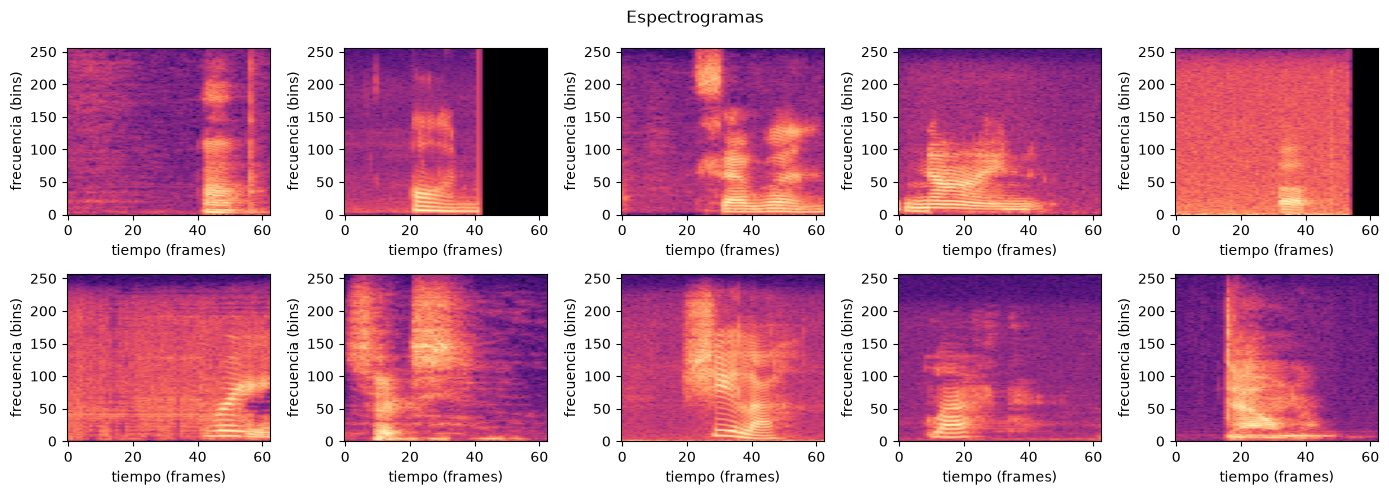

In [19]:
# 1. Abrimos el archivo en modo lectura ("r")
with h5py.File(r"data/X_train_spec.h5", "r") as hf:
    
    # Referencia al archivo en el disco duro (¡no gasta RAM!)
    X_disco = hf["X_spec"]
    
    # Extraemos solo los primeros 10 espectrogramas a la memoria RAM
    X_spec_lote = X_disco[0:10]

# 2. Tu código exacto, pero usando el lote que acabamos de extraer
fig, axes = plt.subplots(2, 5, figsize=(14, 5))
for d, ax in enumerate(axes.ravel()):
    i = d
    # Usamos X_spec_lote en lugar de cargar todo el dataset original
    ax.imshow(X_spec_lote[i, :, :, 0].T, origin="lower", aspect="auto", cmap="magma")
    # ax.set_title(f"Muestra {d}")
    ax.set_xlabel("tiempo (frames)")
    ax.set_ylabel("frecuencia (bins)")

plt.suptitle("Espectrogramas")
plt.tight_layout()
plt.show()

In [44]:
# A. Codificar etiquetas unificando el vocabulario para evitar errores (como _silence_)
le = LabelEncoder()
todas_las_etiquetas = pd.concat([y_train, y_dev, df_test['word']])
le.fit(todas_las_etiquetas)

y_tr_num = le.transform(y_train)
y_va_num = le.transform(y_dev)
y_te_num = le.transform(df_test['word'])
print("Clases totales detectadas:", len(le.classes_))

num_classes=len(le.classes_)

# B. Calcular media y std SOLO de Train, y luego liberar la memoria
print("Calculando media y std de Train...")
with h5py.File(r"data/X_train_spec.h5", "r") as hf_train:
    X_tr_temp = hf_train["X_spec"][:]
    INPUT_SHAPE = X_tr_temp.shape[1:]
    mu = X_tr_temp.mean()
    sd = X_tr_temp.std()
    
# Borramos la variable gigante de la RAM inmediatamente después de calcular
del X_tr_temp
gc.collect() 

print(f"Media: {mu:.4f} | Std: {sd:.4f}")
print("Forma de entrada:", INPUT_SHAPE)

Clases totales detectadas: 36
Calculando media y std de Train...
Media: -5.1500 | Std: 2.7855
Forma de entrada: (63, 257, 1)


In [45]:
class GeneradorLotesHDF5(tf.keras.utils.Sequence):
    def __init__(self, h5_path, etiquetas, batch_size, mu, sd):
        self.h5_path = h5_path
        self.etiquetas = etiquetas 
        self.batch_size = batch_size
        self.mu = mu
        self.sd = sd
        
        with h5py.File(self.h5_path, "r") as hf:
            self.num_samples = hf["X_spec"].shape[0]
            
    def __len__(self):
        return int(np.ceil(self.num_samples / self.batch_size))
        
    def __getitem__(self, i):
        start = i * self.batch_size
        end = min((i + 1) * self.batch_size, self.num_samples)
        
        # Lee SOLO el lote actual del disco
        with h5py.File(self.h5_path, "r") as hf:
            X_lote_crudo = hf["X_spec"][start:end]
            
        # Normaliza este pequeño lote al vuelo
        X_norm = (X_lote_crudo - self.mu) / self.sd
        y_lote = self.etiquetas[start:end]
        
        return X_norm, y_lote

# Definir los parámetros
BATCH_SIZE = 32

# Instanciamos los generadores listos para usarse
train_gen = GeneradorLotesHDF5(r"data/X_train_spec.h5", y_tr_num, BATCH_SIZE, mu, sd)
val_gen = GeneradorLotesHDF5(r"data/X_dev_spec.h5", y_va_num, BATCH_SIZE, mu, sd)
test_gen = GeneradorLotesHDF5(r"data/X_test_spec.h5", y_te_num, BATCH_SIZE, mu, sd)

In [46]:
RESULTADOS = {}
MODELOS = {}

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"¡GPU detectada! TensorFlow usará: {gpus[0]}")
else:
    print("No se detectó GPU. TensorFlow usará la CPU.")

def entrenar_y_evaluar(nombre, modelo, train_gen, val_gen, test_gen, epochs=60, extra_callbacks=()):
    # Mantenemos el compilador igual
    modelo.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=3e-4),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    
    # Mantenemos el Early Stopping
    cbs = [callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
           *extra_callbacks]
    
    t0 = time.time()
    
    # Usamos los generadores en lugar de Xtr, ytr
    # Nota: validation_data acepta un generador directamente.
    # El batch_size ya lo define internamente el generador, así que lo quitamos de model.fit
    hist = modelo.fit(train_gen, 
                      validation_data=val_gen, 
                      epochs=epochs,
                      callbacks=cbs, 
                      verbose=2)
    
    seg = time.time() - t0
    
    # Evaluamos usando el generador de test
    acc = modelo.evaluate(test_gen, verbose=0)[1]
    
    # Guardamos los resultados
    RESULTADOS[nombre] = {"acc": acc, "params": modelo.count_params(),
                          "epocas": len(hist.history["loss"]), "seg": seg}
    MODELOS[nombre] = modelo
    
    print(f"{nombre}: exactitud test = {acc:.3f} | parámetros = {modelo.count_params():,} "
          f"| épocas = {len(hist.history['loss'])} | {seg:.0f} s")
    
    return hist

def graficar_historia(hist, titulo):
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
    ax[0].plot(hist.history["loss"], label="train")
    ax[0].plot(hist.history["val_loss"], label="validación")
    ax[0].set_title(f"{titulo}: pérdida"); ax[0].set_xlabel("época"); ax[0].legend()
    ax[1].plot(hist.history["accuracy"], label="train")
    ax[1].plot(hist.history["val_accuracy"], label="validación")
    ax[1].set_title(f"{titulo}: exactitud"); ax[1].set_xlabel("época"); ax[1].legend()
    plt.tight_layout(); plt.show()




¡GPU detectada! TensorFlow usará: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')


In [47]:
def nivel0_mlp(input_shape):
    return models.Sequential([
        layers.Input(shape=input_shape),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dense(num_classes, activation="softmax"),
    ], name="N0_MLP")

m0 = nivel0_mlp(INPUT_SHAPE)
m0.summary()

Model: "N0_MLP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_6 (Flatten)             │ (None, 16191)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 128)            │     2,072,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 36)             │         4,644 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,077,220 (7.92 MB)

 Trainable params: 2,077,220 (7.92 MB)

 Non-trainable params: 0 (0.00 B)

/home/juan/miniconda3/envs/speech_cmd/lib/python3.11/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/60


I0000 00:00:1793749320.519926  340405 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_265526__.12
I0000 00:00:1793749437.397630  340405 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_265526__.12


2646/2646 - 185s - 70ms/step - accuracy: 0.2077 - loss: 3.0100 - val_accuracy: 0.3193 - val_loss: 2.5200
Epoch 2/60
2646/2646 - 84s - 32ms/step - accuracy: 0.3696 - loss: 2.2813 - val_accuracy: 0.4035 - val_loss: 2.2801
Epoch 3/60
2646/2646 - 84s - 32ms/step - accuracy: 0.4300 - loss: 2.0506 - val_accuracy: 0.4334 - val_loss: 2.1028
Epoch 4/60
2646/2646 - 80s - 30ms/step - accuracy: 0.4638 - loss: 1.9122 - val_accuracy: 0.4557 - val_loss: 1.9511
Epoch 5/60
2646/2646 - 84s - 32ms/step - accuracy: 0.4876 - loss: 1.8320 - val_accuracy: 0.4618 - val_loss: 1.9486
Epoch 6/60
2646/2646 - 81s - 31ms/step - accuracy: 0.5035 - loss: 1.7659 - val_accuracy: 0.4768 - val_loss: 1.8800
Epoch 7/60
2646/2646 - 82s - 31ms/step - accuracy: 0.5189 - loss: 1.6992 - val_accuracy: 0.4787 - val_loss: 1.8968
Epoch 8/60
2646/2646 - 81s - 31ms/step - accuracy: 0.5302 - loss: 1.6547 - val_accuracy: 0.4789 - val_loss: 1.8744
Epoch 9/60
2646/2646 - 79s - 30ms/step - accuracy: 0.5414 - loss: 1.6145 - val_accuracy: 0

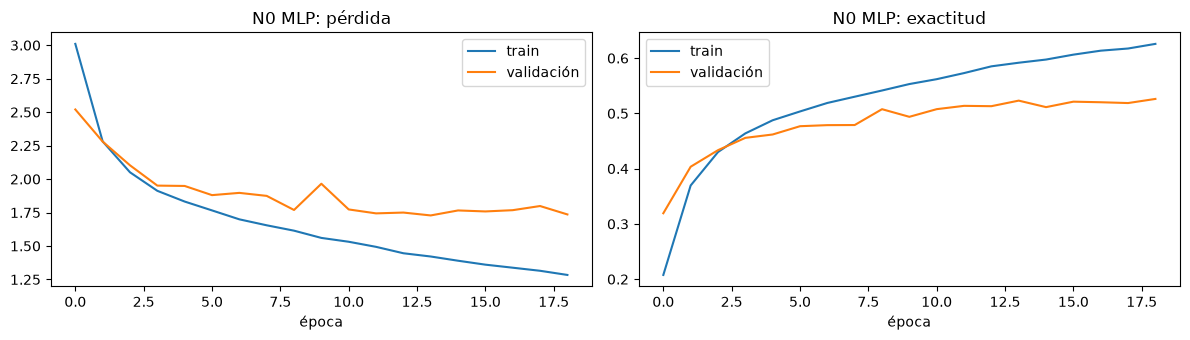

In [48]:
h0 = entrenar_y_evaluar("N0 MLP", m0, train_gen, val_gen, test_gen)
graficar_historia(h0, "N0 MLP")

In [49]:
def nivel1_cnn_minima(input_shape):
    return models.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv2D(8, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(num_classes, activation="softmax"),
    ], name="N1_CNN_minima")

m1 = nivel1_cnn_minima(INPUT_SHAPE)
m1.summary()

Model: "N1_CNN_minima"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 63, 257, 8)     │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 31, 128, 8)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_7 (Flatten)             │ (None, 31744)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 36)             │     1,142,820 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,142,900 (4.36 MB)

 Trainable params: 1,142,900 (4.36 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/60


I0000 00:00:1793751017.329825  340401 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_519336__.20
I0000 00:00:1793751040.092296  340404 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_519336__.20


2646/2646 - 90s - 34ms/step - accuracy: 0.3524 - loss: 2.4290 - val_accuracy: 0.4503 - val_loss: 2.0416
Epoch 2/60
2646/2646 - 82s - 31ms/step - accuracy: 0.5239 - loss: 1.8030 - val_accuracy: 0.5153 - val_loss: 1.8173
Epoch 3/60
2646/2646 - 88s - 33ms/step - accuracy: 0.6073 - loss: 1.5029 - val_accuracy: 0.5255 - val_loss: 1.7478
Epoch 4/60
2646/2646 - 85s - 32ms/step - accuracy: 0.6729 - loss: 1.2696 - val_accuracy: 0.5414 - val_loss: 1.6995
Epoch 5/60
2646/2646 - 86s - 32ms/step - accuracy: 0.7257 - loss: 1.0712 - val_accuracy: 0.5438 - val_loss: 1.6845
Epoch 6/60
2646/2646 - 89s - 34ms/step - accuracy: 0.7724 - loss: 0.8961 - val_accuracy: 0.5419 - val_loss: 1.7282
Epoch 7/60
2646/2646 - 84s - 32ms/step - accuracy: 0.8163 - loss: 0.7411 - val_accuracy: 0.5209 - val_loss: 1.8154
Epoch 8/60
2646/2646 - 87s - 33ms/step - accuracy: 0.8508 - loss: 0.6097 - val_accuracy: 0.5163 - val_loss: 1.8719
Epoch 9/60
2646/2646 - 84s - 32ms/step - accuracy: 0.8836 - loss: 0.4937 - val_accuracy: 0.

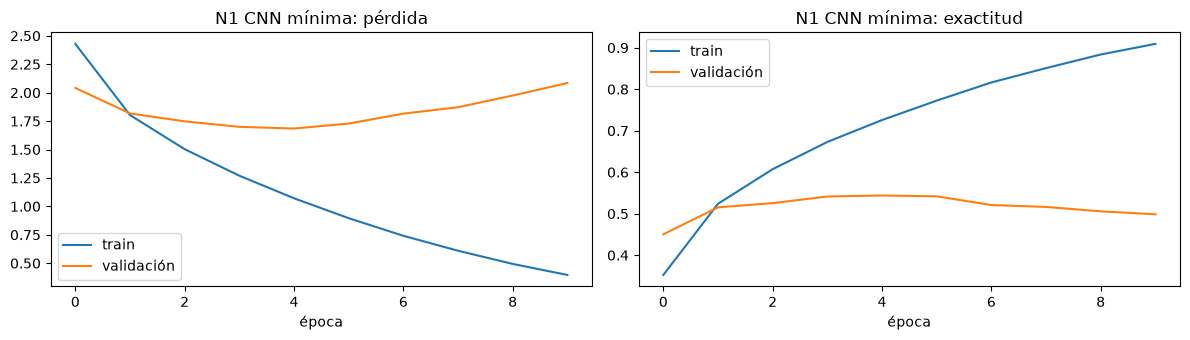

In [50]:
h1 = entrenar_y_evaluar("N1 CNN mínima", m1, train_gen, val_gen, test_gen)
graficar_historia(h1, "N1 CNN mínima")

In [51]:
def bloque_conv_2d(filtros):
    return [
        layers.Conv2D(filtros, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),
    ]

def nivel2_cnn(input_shape, cabezal="flatten"):
    capas = [layers.Input(shape=input_shape)]
    for f in (16, 32):
        capas += bloque_conv_2d(f)
    capas += [layers.Conv2D(64, (3, 3), activation="relu", padding="same")]
    if cabezal == "flatten":
        capas += [layers.MaxPooling2D((2, 2)), layers.Flatten()]
    else:
        capas += [layers.GlobalAveragePooling2D()]
    capas += [layers.Dense(64, activation="relu"),
              layers.Dropout(0.3),
              layers.Dense(num_classes, activation="softmax")]
    return models.Sequential(capas, name=f"N2_{cabezal}")

m2_flat = nivel2_cnn(INPUT_SHAPE, "flatten")

In [53]:
h2_flat = entrenar_y_evaluar("N2 Flatten", m2_flat, train_gen, val_gen, test_gen)

Epoch 1/60


I0000 00:00:1793752159.994607  340407 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_699173__.40
I0000 00:00:1793752231.962950  340407 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_699173__.40


2646/2646 - 100s - 38ms/step - accuracy: 0.5817 - loss: 1.3370 - val_accuracy: 0.7613 - val_loss: 0.8281
Epoch 2/60
2646/2646 - 79s - 30ms/step - accuracy: 0.6257 - loss: 1.1872 - val_accuracy: 0.7839 - val_loss: 0.7492
Epoch 3/60
2646/2646 - 82s - 31ms/step - accuracy: 0.6617 - loss: 1.0714 - val_accuracy: 0.8053 - val_loss: 0.6730
Epoch 4/60
2646/2646 - 78s - 29ms/step - accuracy: 0.6890 - loss: 0.9827 - val_accuracy: 0.8131 - val_loss: 0.6420
Epoch 5/60
2646/2646 - 88s - 33ms/step - accuracy: 0.7124 - loss: 0.8986 - val_accuracy: 0.8231 - val_loss: 0.6050
Epoch 6/60
2646/2646 - 85s - 32ms/step - accuracy: 0.7349 - loss: 0.8240 - val_accuracy: 0.8341 - val_loss: 0.5776
Epoch 7/60
2646/2646 - 81s - 31ms/step - accuracy: 0.7539 - loss: 0.7617 - val_accuracy: 0.8321 - val_loss: 0.5822
Epoch 8/60
2646/2646 - 86s - 32ms/step - accuracy: 0.7742 - loss: 0.6975 - val_accuracy: 0.8399 - val_loss: 0.5467
Epoch 9/60
2646/2646 - 81s - 31ms/step - accuracy: 0.7859 - loss: 0.6570 - val_accuracy: 0

In [ ]:
m2_gap = nivel2_cnn(INPUT_SHAPE, "gap")

In [55]:
h2_gap = entrenar_y_evaluar("N2 GAP", m2_gap, train_gen, val_gen, test_gen)

Epoch 1/60


I0000 00:00:1793753531.139175  340403 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_914471__.33
I0000 00:00:1793753580.038697  340404 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_914471__.33


2646/2646 - 92s - 35ms/step - accuracy: 0.0764 - loss: 3.3935 - val_accuracy: 0.1076 - val_loss: 3.2576
Epoch 2/60
2646/2646 - 86s - 33ms/step - accuracy: 0.1368 - loss: 3.1144 - val_accuracy: 0.1917 - val_loss: 2.9070
Epoch 3/60
2646/2646 - 87s - 33ms/step - accuracy: 0.1870 - loss: 2.8765 - val_accuracy: 0.2326 - val_loss: 2.7329
Epoch 4/60
2646/2646 - 82s - 31ms/step - accuracy: 0.2239 - loss: 2.7182 - val_accuracy: 0.2726 - val_loss: 2.5733
Epoch 5/60
2646/2646 - 82s - 31ms/step - accuracy: 0.2541 - loss: 2.5983 - val_accuracy: 0.3166 - val_loss: 2.4342
Epoch 6/60
2646/2646 - 83s - 31ms/step - accuracy: 0.2814 - loss: 2.4923 - val_accuracy: 0.3347 - val_loss: 2.3224
Epoch 7/60
2646/2646 - 81s - 31ms/step - accuracy: 0.3067 - loss: 2.3989 - val_accuracy: 0.3716 - val_loss: 2.2079
Epoch 8/60
2646/2646 - 84s - 32ms/step - accuracy: 0.3273 - loss: 2.3112 - val_accuracy: 0.3801 - val_loss: 2.1534
Epoch 9/60
2646/2646 - 84s - 32ms/step - accuracy: 0.3485 - loss: 2.2392 - val_accuracy: 0.

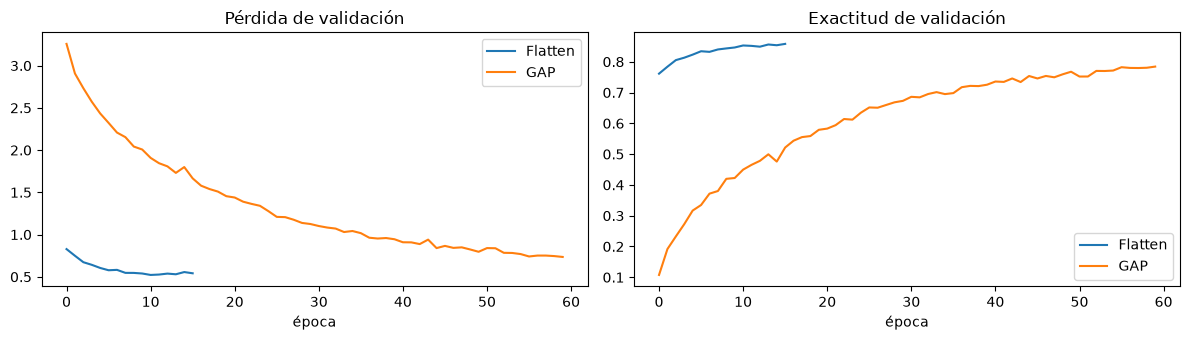

In [56]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for nombre, h in [("Flatten", h2_flat), ("GAP", h2_gap)]:
    ax[0].plot(h.history["val_loss"], label=nombre)
    ax[1].plot(h.history["val_accuracy"], label=nombre)
ax[0].set_title("Pérdida de validación"); ax[0].set_xlabel("época"); ax[0].legend()
ax[1].set_title("Exactitud de validación"); ax[1].set_xlabel("época"); ax[1].legend()
plt.tight_layout(); plt.show()

In [57]:
def bloque_conv_bn(filtros):
    return [
        layers.Conv2D(filtros, (3, 3), padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D((2, 2)),
    ]

def nivel3_cnn_regularizada(input_shape):
    capas = [layers.Input(shape=input_shape)]
    for f in (16, 32, 64):
        capas += bloque_conv_bn(f)
    capas += [layers.Flatten(),
              layers.Dense(64, activation="relu"),
              layers.Dropout(0.4),
              layers.Dense(num_classes, activation="softmax")]
    return models.Sequential(capas, name="N3_CNN_regularizada")

m3 = nivel3_cnn_regularizada(INPUT_SHAPE)
m3.summary()
reduce_lr = callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, verbose=0)

Model: "N3_CNN_regularizada"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_11 (Conv2D)              │ (None, 63, 257, 16)    │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 63, 257, 16)    │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 63, 257, 16)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 31, 128, 16)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 31, 128, 32)    │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 31, 128, 32)    │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 31, 128, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 15, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 15, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 15, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 15, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 7, 32, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_9 (Flatten)             │ (None, 14336)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 64)             │       917,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 36)             │         2,340 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 943,540 (3.60 MB)

 Trainable params: 943,316 (3.60 MB)

 Non-trainable params: 224 (896.00 B)

Epoch 1/60


I0000 00:00:1793758454.487476  340401 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1714765__.55
I0000 00:00:1793758480.642262  340401 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1714765__.55


2646/2646 - 99s - 38ms/step - accuracy: 0.0371 - loss: 3.5499 - val_accuracy: 0.0383 - val_loss: 3.5253 - learning_rate: 3.0000e-04
Epoch 2/60
2646/2646 - 84s - 32ms/step - accuracy: 0.0381 - loss: 3.5155 - val_accuracy: 0.0383 - val_loss: 3.5085 - learning_rate: 3.0000e-04
Epoch 3/60
2646/2646 - 84s - 32ms/step - accuracy: 0.0376 - loss: 3.5053 - val_accuracy: 0.0383 - val_loss: 3.5027 - learning_rate: 3.0000e-04
Epoch 4/60
2646/2646 - 85s - 32ms/step - accuracy: 0.0382 - loss: 3.5014 - val_accuracy: 0.0383 - val_loss: 3.5002 - learning_rate: 3.0000e-04
Epoch 5/60
2646/2646 - 82s - 31ms/step - accuracy: 0.0372 - loss: 3.4997 - val_accuracy: 0.0383 - val_loss: 3.4991 - learning_rate: 3.0000e-04
Epoch 6/60
2646/2646 - 82s - 31ms/step - accuracy: 0.0379 - loss: 3.4988 - val_accuracy: 0.0383 - val_loss: 3.4985 - learning_rate: 3.0000e-04
Epoch 7/60
2646/2646 - 83s - 31ms/step - accuracy: 0.0380 - loss: 3.4984 - val_accuracy: 0.0383 - val_loss: 3.4981 - learning_rate: 3.0000e-04
Epoch 8/60

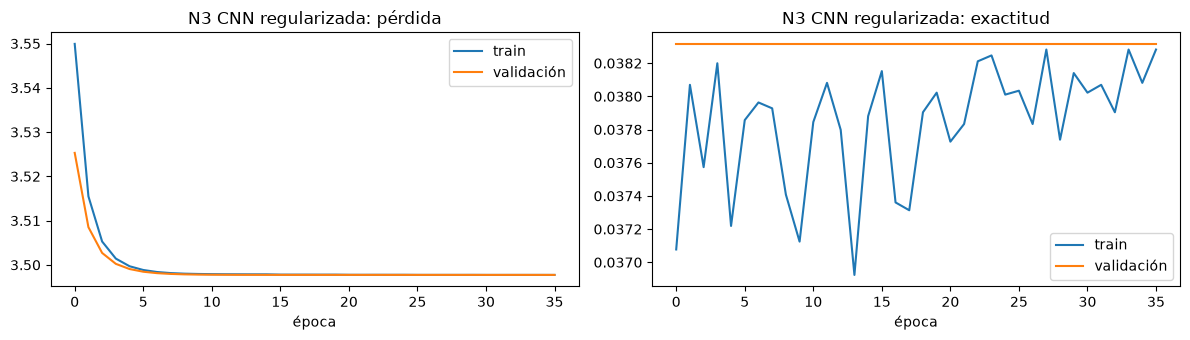

In [58]:
h3 = entrenar_y_evaluar("N3 CNN regularizada", m3, train_gen, val_gen, test_gen,
                        extra_callbacks=[reduce_lr])
graficar_historia(h3, "N3 CNN regularizada")

In [59]:
def nivel4_crnn(input_shape):
    T = input_shape[0] // 4   # tiempo después de dos pools de 2
    F = input_shape[1] // 4   # frecuencia después de dos pools de 2
    return models.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv2D(16, (3, 3), padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(32, (3, 3), padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Reshape((T, F * 32)),   # secuencia de T pasos, cada uno con F*32 valores
        layers.GRU(64),
        layers.Dropout(0.3),
        layers.Dense(num_classes, activation="softmax"),
    ], name="N4_CRNN")

m4 = nivel4_crnn(INPUT_SHAPE)
m4.summary()

Model: "N4_CRNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_14 (Conv2D)              │ (None, 63, 257, 16)    │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 63, 257, 16)    │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 63, 257, 16)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 31, 128, 16)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 31, 128, 32)    │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 31, 128, 32)    │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 31, 128, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 15, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 15, 2048)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 64)             │       405,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 36)             │         2,340 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 413,172 (1.58 MB)

 Trainable params: 413,076 (1.58 MB)

 Non-trainable params: 96 (384.00 B)

Epoch 1/60
2646/2646 - 108s - 41ms/step - accuracy: 0.4904 - loss: 1.9182 - val_accuracy: 0.7747 - val_loss: 0.9155 - learning_rate: 3.0000e-04
Epoch 2/60
2646/2646 - 95s - 36ms/step - accuracy: 0.7799 - loss: 0.8222 - val_accuracy: 0.8427 - val_loss: 0.5982 - learning_rate: 3.0000e-04
Epoch 3/60
2646/2646 - 96s - 36ms/step - accuracy: 0.8390 - loss: 0.5903 - val_accuracy: 0.8710 - val_loss: 0.4660 - learning_rate: 3.0000e-04
Epoch 4/60
2646/2646 - 96s - 36ms/step - accuracy: 0.8673 - loss: 0.4772 - val_accuracy: 0.8877 - val_loss: 0.4048 - learning_rate: 3.0000e-04
Epoch 5/60
2646/2646 - 95s - 36ms/step - accuracy: 0.8849 - loss: 0.4080 - val_accuracy: 0.8990 - val_loss: 0.3590 - learning_rate: 3.0000e-04
Epoch 6/60
2646/2646 - 94s - 35ms/step - accuracy: 0.9010 - loss: 0.3514 - val_accuracy: 0.9063 - val_loss: 0.3251 - learning_rate: 3.0000e-04
Epoch 7/60
2646/2646 - 94s - 36ms/step - accuracy: 0.9120 - loss: 0.3092 - val_accuracy: 0.9086 - val_loss: 0.3055 - learning_rate: 3.0000e-0

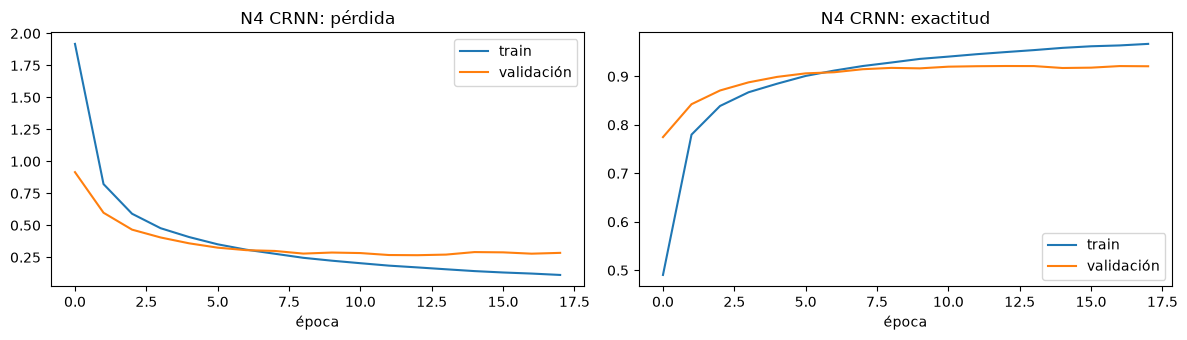

In [60]:
h4 = entrenar_y_evaluar("N4 CRNN", m4, train_gen, val_gen, test_gen,
                        extra_callbacks=[reduce_lr])
graficar_historia(h4, "N4 CRNN")